In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
fs=500.0              #Sampling rate, samples per second
T=2.0                 #total duration, seconds
t=np.arange(0,T,1/fs)# N= fs*t = 1000 samples

In [ ]:
#three pure tones plus noise - we KNOW the answer, which is the point
x = 1.0*np.sin(2*np.pi*5*t)\
+0.5*np.sin(2*np.pi*20*t)\
+0.25*np.sin(2*np.pi*50*t)\
+0.20*np.random.default_rng(0).standard_normal(t.size)


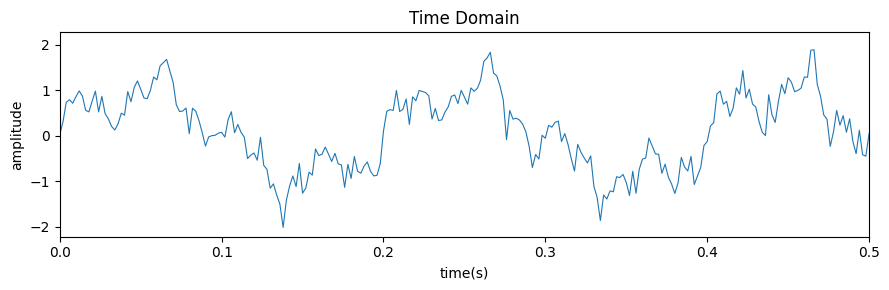

In [ ]:
plt.figure(figsize=(9,3))
plt.plot(t,x,lw=0.8);plt.xlim(0,0.5)
plt.xlabel('time(s)');plt.ylabel('amplitude');plt.title('Time Domain')
plt.tight_layout();
plt.show()

In [30]:
N = t.size
X = np.fft.rfft (x) # real input --> one sided spectrum
f = np.fft.rfftfreq (N, 1 /fs)

In [31]:
# amplitude in the SAME units as x: divide by N/2, not by N
amp = np.abs (X) * 2.0 / N
amp[0] /= 2.0 # DC bin is not doubled

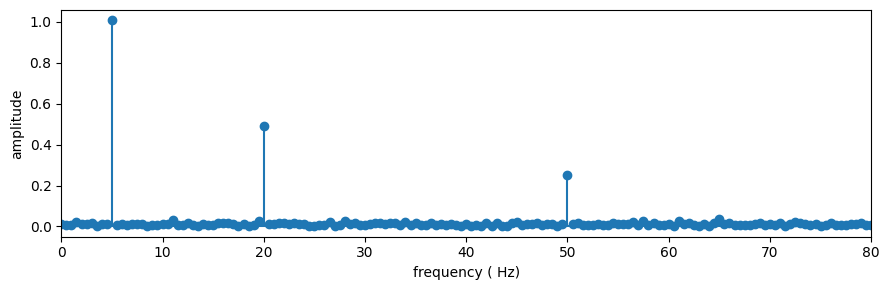

In [33]:
plt.figure(figsize=( 9,3))
plt.stem (f, amp, basefmt='')
plt.xlim (0 , 80 ); plt.xlabel ('frequency ( Hz)'); plt.ylabel('amplitude')
plt.tight_layout (); plt.show()

In [35]:
peaks = f[amp >0.1]
print('peaks at:', np.round (peaks, 2 )) # expect 5, 20 and 50 Hz

peaks at: [ 5. 20. 50.]


In [70]:
from scipy.integrate import solve_ivp

In [69]:
g,L =9.81,1.0   #gravity, length(m)
b=0.0           #damping coefficient (0.0=undamped)

In [73]:
def pendulum(t,y):        #y=[theta,omega] NOTE: (t,y), not (y,t)
  theta,omega =y
  return [omega,-b*omega-(g/L)*np.sin(theta)]

In [74]:
theta0=np.deg2rad(170)         #Always convert: np.sin expects radians
t_eval=np.linspace(0,20,4000)
sol=solve_ivp(pendulum,[0,20],[theta0,0],t_eval=t_eval,rtol=1e-9,atol=1e-12)

predicted period=2.0061 s


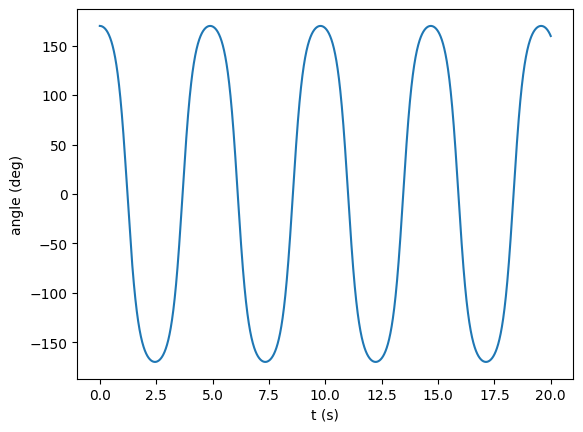

In [75]:
T_small=2*np.pi*np.sqrt(L/g)  #small-angle prediction
print(f'predicted period={T_small:.4f} s')
plt.plot(sol.t,np.rad2deg(sol.y[0]));plt.xlabel('t (s)')
plt.ylabel('angle (deg)'); plt.show()